# run_python: giving Escalator a code runner on AWS Lambda

Escalator is a Strands agent where a 2B decision model sends easy questions to Amazon Nova Micro and hard ones to Claude Haiku 4.5 on Amazon Bedrock. The decider can tell whether an answer addresses the question, but not whether a calculation is right. This notebook covers the one tool added for the weekend challenge: `run_python`, which runs model-written Python in an AWS Lambda sandbox.

It runs without AWS. The sandbox code is called locally (the same `handler` that Lambda runs), and the benchmark section reads the saved results in `bench/reported/`. The last section calls Lambda and Bedrock for real; it is off unless you set `RUN_LIVE = True`.

Code: https://github.com/Swayam-Ch/escalator/tree/run-python-tool · Video: https://youtu.be/3geFHbr-2kY

In [1]:
import json
import os
import sys
from pathlib import Path

from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "bench"), str(ROOT / "lambda" / "run_python")]

from handler import handler                      # what AWS Lambda runs
from escalator.tools import format_result, make_run_python
from run_tool_bench import short, summarise

RUN_LIVE = False   # True invokes the deployed Lambda function and Amazon Bedrock (a few cents)

## 1. The sandbox

`lambda/run_python/handler.py` runs the program in a child process with an empty environment and a time limit, and returns what it printed. Here it is called directly, with the same event Lambda receives.

In [2]:
handler({"code": "print(48917 * 7382)"})

{'stdout': '361105294\n', 'stderr': '', 'exit_code': 0, 'timed_out': False}

The function's own AWS credentials are environment variables inside Lambda. The child process gets an empty environment, so model-written code can't read them:

In [3]:
os.environ["AWS_SECRET_ACCESS_KEY"] = "pretend-this-is-the-lambda-role-key"
handler({"code": "import os; print(os.environ.get('AWS_SECRET_ACCESS_KEY'))"})

{'stdout': 'None\n', 'stderr': '', 'exit_code': 0, 'timed_out': False}

Runaway code is stopped, and errors come back to the model as text it can read and fix:

In [4]:
print(handler({"code": "while True: pass", "timeout": 1}))
print(handler({"code": "1 / 0"})["stderr"].strip().splitlines()[-1])

{'stdout': '', 'stderr': '', 'exit_code': None, 'timed_out': True}
ZeroDivisionError: division by zero


## 2. The Strands tool

`make_run_python()` builds an ordinary Strands `@tool`. By default it invokes the Lambda function with boto3; here it gets the local handler instead. `log` records every run, which is how `escalator --tool` shows the code it ran.

In [5]:
runs = []
run_python = make_run_python(invoke=handler, log=runs)

program = '''
r, n = 0.07 / 12, 240
print(round(500 * ((1 + r) ** n - 1) / r, 2))
'''
print(run_python(code=program))
print(runs[0]["result"])

exit code 0
stdout:
260463.33

{'stdout': '260463.33\n', 'stderr': '', 'exit_code': 0, 'timed_out': False}


This is the description and input schema the model sees. Any Strands agent can use the tool with `Agent(model=..., tools=[make_run_python()])`.

In [6]:
spec = run_python.tool_spec
print(spec["description"])
spec["inputSchema"]["json"]

Run a short Python 3 program in an isolated sandbox and return what it printed.

Use it for calculations, counting, dates, and checking what code outputs. The program has
the standard library only, no files from the conversation, and a 5-second limit.


{'properties': {'code': {'description': 'A complete Python 3 program. Print every value you need to see.',
   'type': 'string'}},
 'required': ['code'],
 'type': 'object'}

## 3. Before and after

18 questions with exact answers ([`bench/calc_questions.jsonl`](../bench/calc_questions.jsonl)), each asked to Nova Micro and Claude Haiku 4.5 with the tool off and on. Correctness is checked by code against the answer and a tolerance, with no LLM judge.

# run_python tool: before and after

18 calculation questions with exact answers.

| Model | Tool | Correct | LLM cost | Median latency | Code runs | No answer line |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| nova-micro-v1 | off | 2/18 | $0.000070 | 766 ms | 0 | 0 |
| nova-micro-v1 | on | 13/18 | $0.001452 | 2093 ms | 21 | 0 |
| claude-haiku-4-5-20251001-v1 | off | 11/18 | $0.041522 | 2364 ms | 0 | 0 |
| claude-haiku-4-5-20251001-v1 | on | 18/18 | $0.055232 | 3164 ms | 19 | 0 |



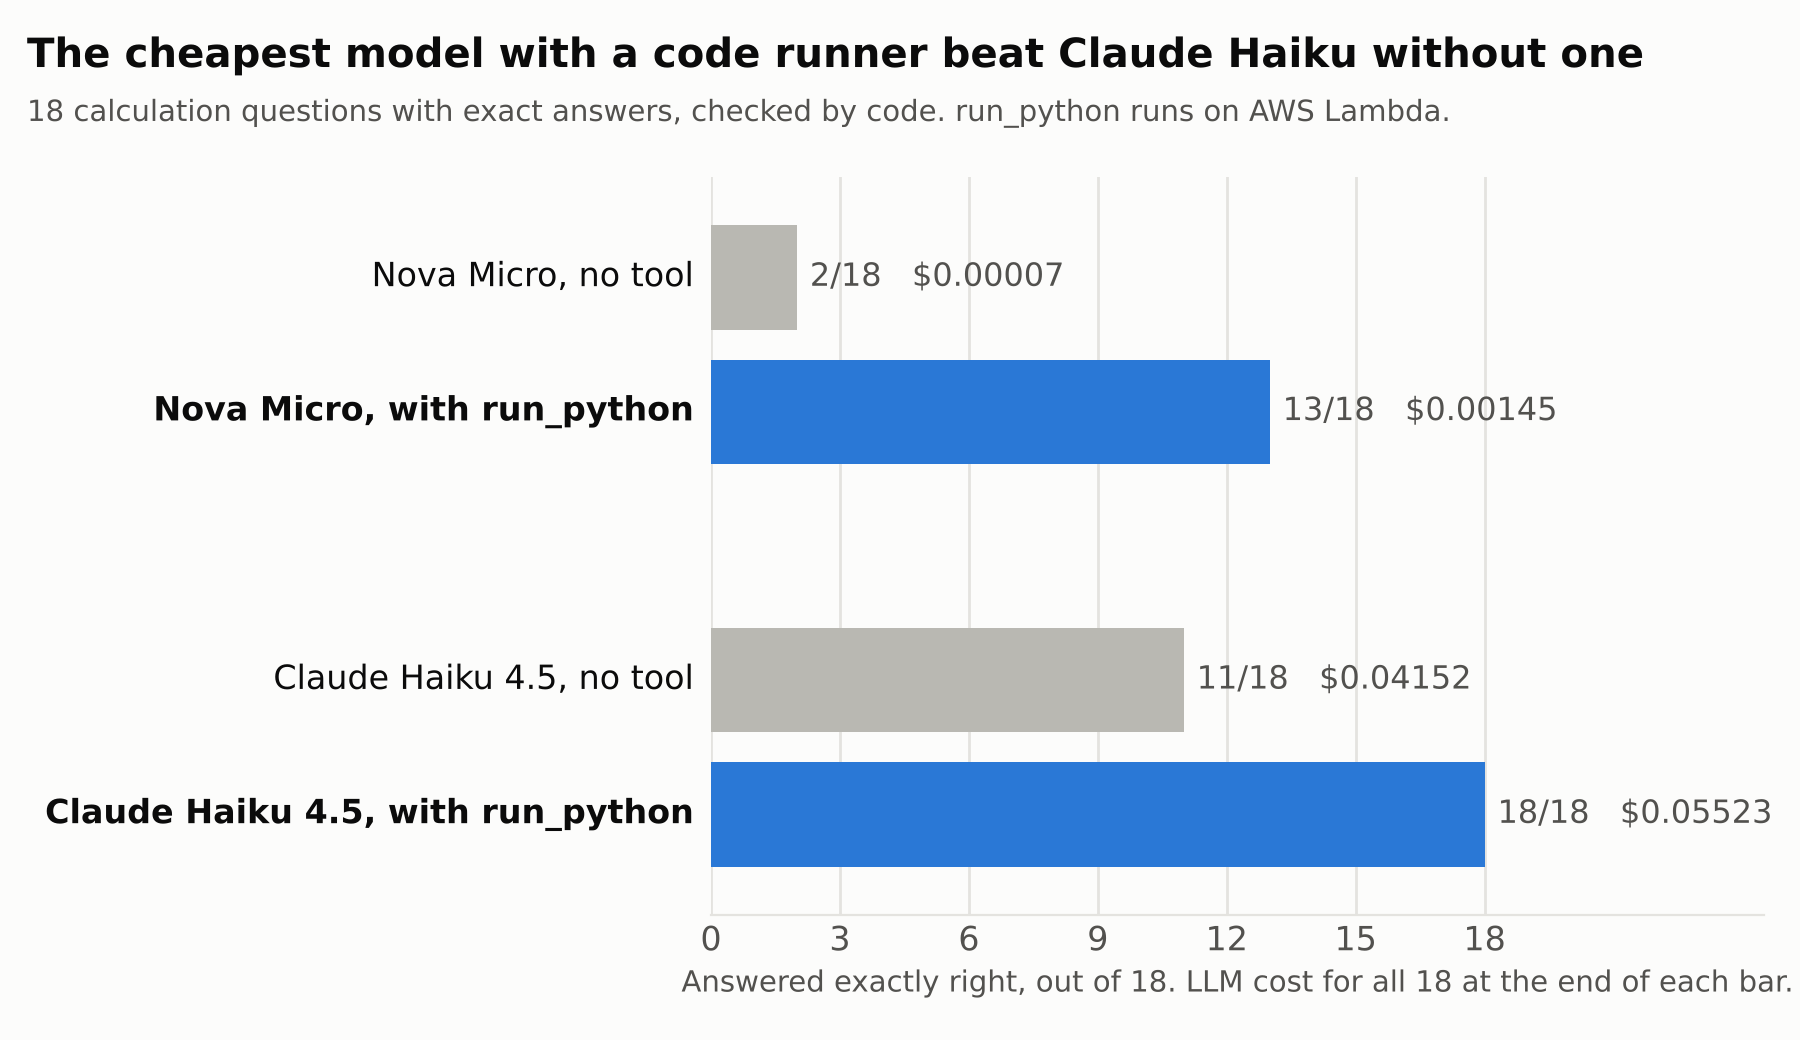

In [7]:
rows = [json.loads(line) for line in (ROOT / "bench" / "reported" / "tool-results.jsonl").read_text().splitlines() if line.strip()]
configs = list(dict.fromkeys((r["model"], r["tool"]) for r in rows))
display(Markdown(summarise(rows, configs).split("## Per question")[0]))
display(Image(filename=str(ROOT / "docs" / "tool-before-after.png"), width=760))

In [8]:
def score(model_part, tool):
    mine = [r for r in rows if model_part in r["model"] and r["tool"] == tool]
    return sum(r["correct"] for r in mine), sum(r["cost"] for r in mine)

nova_on, nova_on_cost = score("nova", True)
haiku_off, haiku_off_cost = score("haiku", False)
print(f"Nova Micro + run_python: {nova_on}/18 for ${nova_on_cost:.5f}")
print(f"Claude Haiku, no tool:   {haiku_off}/18 for ${haiku_off_cost:.5f}  ({haiku_off_cost / nova_on_cost:.0f}x the cost)")

Nova Micro + run_python: 13/18 for $0.00145
Claude Haiku, no tool:   11/18 for $0.04152  (29x the cost)


## 4. Where the tool made the difference

Questions a model got wrong without the tool and right with it, and what it said without the tool.

In [9]:
by = {(r["id"], short(r["model"]), r["tool"]): r for r in rows}
lines = ["| Question | Model | Without the tool | Answer |", "| --- | --- | ---: | ---: |"]
for (qid, model, tool), r in by.items():
    if tool and r["correct"] and not by[(qid, model, False)]["correct"]:
        lines.append(f"| `{qid}` {r['kind']} | {model} | {by[(qid, model, False)]['predicted']} | {r['answer']} |")
display(Markdown("\n".join(lines)))

| Question | Model | Without the tool | Answer |
| --- | --- | ---: | ---: |
| `calc-01` finance | claude-haiku-4-5-20251001-v1 | 177033.25 | 260463.33 |
| `calc-02` finance | nova-micro-v1 | 377.0 | 386.66 |
| `calc-03` finance | claude-haiku-4-5-20251001-v1 | 13493.53 | 13678.52 |
| `calc-04` arithmetic | nova-micro-v1 | 358619774.0 | 361105294 |
| `calc-04` arithmetic | claude-haiku-4-5-20251001-v1 | 361012894.0 | 361105294 |
| `calc-05` arithmetic | claude-haiku-4-5-20251001-v1 | 1111.118 | 1111.111 |
| `calc-06` arithmetic | nova-micro-v1 | 1.0 | 16 |
| `calc-07` arithmetic | nova-micro-v1 | 10.0 | 115 |
| `calc-08` dates | nova-micro-v1 | 273.0 | 301 |
| `calc-09` dates | claude-haiku-4-5-20251001-v1 | 3.0 | 2 |
| `calc-11` counting | nova-micro-v1 | 784.0 | 1229 |
| `calc-12` counting | nova-micro-v1 | 7.0 | 18 |
| `calc-12` counting | claude-haiku-4-5-20251001-v1 | 16.0 | 18 |
| `calc-14` counting | nova-micro-v1 | 15480087559209.0 | 1548008755920 |
| `calc-15` code | nova-micro-v1 | 245145.0 | 112761 |
| `calc-15` code | claude-haiku-4-5-20251001-v1 | 111069.0 | 112761 |
| `calc-16` code | nova-micro-v1 | 8.0 | 111 |
| `calc-18` statistics | nova-micro-v1 | 7.6522 | 7.12 |

## 5. What still fails

Nova Micro missed 5 questions even with the tool. The end of each reply shows what went wrong: a formatting slip after a correct result, rounding, a 13-cent error, a wrong program, and an estimate where the exact value was asked for.

In [10]:
for r in rows:
    if r["tool"] and not r["correct"]:
        tail = r["text"].strip().splitlines()[-1]
        print(f"{r['id']}  expected {r['answer']:<12} got {r['predicted']:<12} code runs: {r['tool_calls']}   last line: {tail}")

calc-01  expected 260463.33    got 260463.2     code runs: 2   last line: ANSWER: 260463.2
calc-03  expected 13678.52     got 1367852.0    code runs: 2   last line: ANSWER: 1367852
calc-05  expected 1111.111     got 1111.0       code runs: 1   last line: ANSWER: 1111
calc-13  expected 242          got 30.0         code runs: 1   last line: ANSWER: 30
calc-17  expected 14.7         got 14.7684      code runs: 1   last line: ANSWER: 14.7684


## 6. Live run (optional)

With `RUN_LIVE = True`, this asks Claude Haiku the investment question through Amazon Bedrock with the real Lambda-backed tool, then prints the code it ran. It needs AWS credentials, Bedrock model access and the deployed function (`python deploy/deploy_run_python.py`).

In [11]:
if RUN_LIVE:
    from escalator.agent import LARGE_MODEL, SYSTEM_PROMPT, bedrock_call

    live_runs = []
    reply = bedrock_call(LARGE_MODEL, SYSTEM_PROMPT,
                         "If I invest $500 a month for 20 years at 7% a year, compounded monthly, what is the final balance?",
                         [make_run_python(log=live_runs)])
    for run in live_runs:
        print(run["code"], "\n->", run["result"]["stdout"])
    print(reply.text, f"\n\n${reply.cost_usd:.6f}, {reply.latency_ms:.0f} ms, ran code {reply.tool_calls}x")
else:
    print("Skipped. Set RUN_LIVE = True to call AWS Lambda and Amazon Bedrock.")

Skipped. Set RUN_LIVE = True to call AWS Lambda and Amazon Bedrock.
